In [1]:
import numpy as np
import scipy.stats as stats
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd

sns.set_style('darkgrid')

%config InlineBackend.figure_format = 'retina'
%matplotlib inline

In [2]:
boston_file = './datasets/housing.csv'

In [3]:
df = pd.read_csv(boston_file,index_col=None)
df.head(5)

,CRIM,ZN,INDUS,CHAS,NOX,RM,AGE,DIS,RAD,TAX,PTRATIO,B,LSTAT,MEDV
0,0.00632,18.0,2.31,0,0.538,6.575,65.2,"4,09",1,296,15.3,396.90,4.98,24.0
1,0.02731,0.0,7.07,0,0.469,6.421,78.9,"4,9671",2,242,17.8,396.90,9.14,21.6
2,0.02729,0.0,7.07,0,0.469,7.185,61.1,"4,9671",2,242,17.8,392.83,4.03,34.7
3,0.03237,0.0,2.18,0,0.458,6.998,45.8,"6,0622",3,222,18.7,394.63,2.94,33.4
4,0.06905,0.0,2.18,0,0.458,7.147,54.2,"6,0622",3,222,18.7,396.90,5.33,36.2


In [4]:
###### Since the original file had an extra column, I deleted it and saved it back
#df.drop('Unnamed: 0',axis=1, inplace=True)
#df.head(2)
#df.to_csv(boston_file,index=False)

In [ ]:
'''^^^ As this was part of the lesson I reverted this change --Sam '''

In [5]:
df.dtypes

CRIM       float64
ZN         float64
INDUS      float64
CHAS         int64
NOX        float64
RM         float64
AGE        float64
DIS         object
RAD         object
TAX          int64
PTRATIO    float64
B          float64
LSTAT      float64
MEDV       float64
dtype: object

In [6]:
df.DIS[0]

'4,09'

In [7]:
df.DIS = df.DIS.map(lambda x : float('.'.join(x.split(','))))
df.head()

,CRIM,ZN,INDUS,CHAS,NOX,RM,AGE,DIS,RAD,TAX,PTRATIO,B,LSTAT,MEDV
0,0.00632,18.0,2.31,0,0.538,6.575,65.2,4.0900,1,296,15.3,396.90,4.98,24.0
1,0.02731,0.0,7.07,0,0.469,6.421,78.9,4.9671,2,242,17.8,396.90,9.14,21.6
2,0.02729,0.0,7.07,0,0.469,7.185,61.1,4.9671,2,242,17.8,392.83,4.03,34.7
3,0.03237,0.0,2.18,0,0.458,6.998,45.8,6.0622,3,222,18.7,394.63,2.94,33.4
4,0.06905,0.0,2.18,0,0.458,7.147,54.2,6.0622,3,222,18.7,396.90,5.33,36.2


In [8]:
df.RAD.unique()

array(['1', '2', '3', '5', '4', '?', '8', '6', '7', '24'], dtype=object)

In [9]:
df.RAD = df.RAD.map(lambda x: np.nan if x == '?' else float(x))
df.head()

,CRIM,ZN,INDUS,CHAS,NOX,RM,AGE,DIS,RAD,TAX,PTRATIO,B,LSTAT,MEDV
0,0.00632,18.0,2.31,0,0.538,6.575,65.2,4.0900,1.0,296,15.3,396.90,4.98,24.0
1,0.02731,0.0,7.07,0,0.469,6.421,78.9,4.9671,2.0,242,17.8,396.90,9.14,21.6
2,0.02729,0.0,7.07,0,0.469,7.185,61.1,4.9671,2.0,242,17.8,392.83,4.03,34.7
3,0.03237,0.0,2.18,0,0.458,6.998,45.8,6.0622,3.0,222,18.7,394.63,2.94,33.4
4,0.06905,0.0,2.18,0,0.458,7.147,54.2,6.0622,3.0,222,18.7,396.90,5.33,36.2


In [10]:
df.isnull().sum()

CRIM        0
ZN          0
INDUS       0
CHAS        0
NOX         0
RM          0
AGE         0
DIS         0
RAD        40
TAX         0
PTRATIO     0
B           0
LSTAT       0
MEDV        0
dtype: int64

In [11]:
df.dropna(inplace=True)

In [13]:
df.rename(columns={
        'CRIM':'rate_of_crime',
        'ZN':'residential_zone_pct',
        'INDUS':'business_zone_pct',
        'CHAS':'borders_river',
        'NOX':'oxide_concentration',
        'RM':'average_rooms',
        'AGE':'owner_occup_pct',
        'DIS':'dist_to_work',
        'RAD':'access_to_highway',
        'TAX':'property_tax',
        'PTRATIO':'student_teacher_ratio',
        'B':'black_stat',
        'LSTAT':'pct_underclass',
        'MEDV':'home_median_value'
    }, inplace=True)

In [14]:
df.head(2)

,rate_of_crime,residential_zone_pct,business_zone_pct,borders_river,oxide_concentration,average_rooms,owner_occup_pct,dist_to_work,access_to_highway,property_tax,student_teacher_ratio,black_stat,pct_underclass,home_median_value
0,0.00632,18.0,2.31,0,0.538,6.575,65.2,4.0900,1.0,296,15.3,396.9,4.98,24.0
1,0.02731,0.0,7.07,0,0.469,6.421,78.9,4.9671,2.0,242,17.8,396.9,9.14,21.6


In [15]:
df.describe()

,rate_of_crime,residential_zone_pct,business_zone_pct,borders_river,oxide_concentration,average_rooms,owner_occup_pct,dist_to_work,access_to_highway,property_tax,student_teacher_ratio,black_stat,pct_underclass,home_median_value
count,466.000000,466.000000,466.000000,466.000000,466.000000,466.000000,466.000000,466.000000,466.000000,466.000000,466.000000,466.000000,466.000000,466.000000
mean,3.326334,11.154506,11.144292,0.075107,0.555840,6.272489,68.504506,3.811963,9.611588,410.049356,18.462876,358.207897,12.650129,22.484120
std,7.095767,22.731621,6.820913,0.263848,0.116818,0.696995,28.023878,2.123668,8.735627,168.921219,2.167158,88.884020,7.068120,9.017586
min,0.006320,0.000000,0.740000,0.000000,0.389000,3.561000,6.000000,1.129600,1.000000,187.000000,12.600000,2.520000,1.730000,5.000000
25%,0.083235,0.000000,5.190000,0.000000,0.450000,5.884250,45.450000,2.101425,4.000000,280.250000,17.400000,375.912500,7.125000,16.800000
50%,0.256355,0.000000,9.690000,0.000000,0.538000,6.189000,77.150000,3.207450,5.000000,330.000000,19.050000,391.705000,11.300000,21.200000
75%,3.689387,12.500000,18.100000,0.000000,0.624000,6.618750,93.975000,5.213925,24.000000,666.000000,20.200000,396.397500,16.955000,25.000000
max,73.534100,100.000000,27.740000,1.000000,0.871000,8.780000,100.000000,12.126500,24.000000,711.000000,22.000000,396.900000,37.970000,50.000000


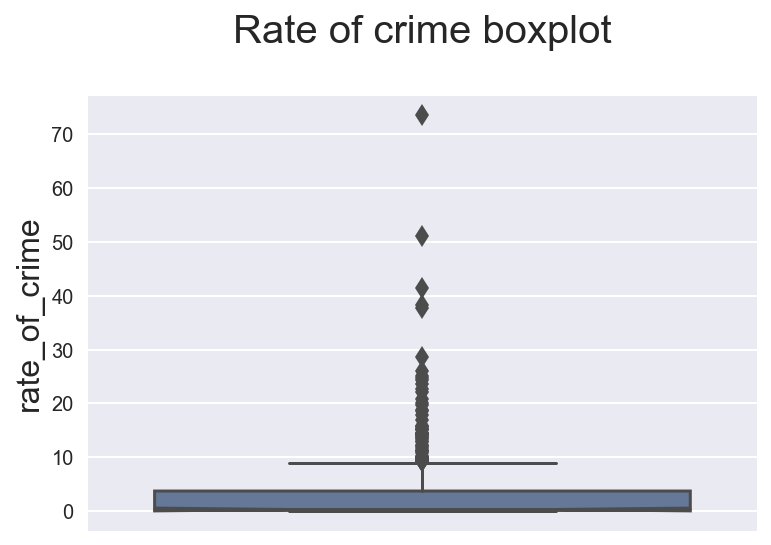

In [16]:
# rate of crime
fig = plt.figure(figsize=(6,4))
ax = fig.gca()

ax = sns.boxplot(df.rate_of_crime, orient='v',
                fliersize=8, linewidth=1.5, notch=True,
                saturation=0.5, ax=ax)

ax.set_ylabel('rate_of_crime', fontsize=16)
ax.set_title('Rate of crime boxplot\n', fontsize=20)

plt.show()

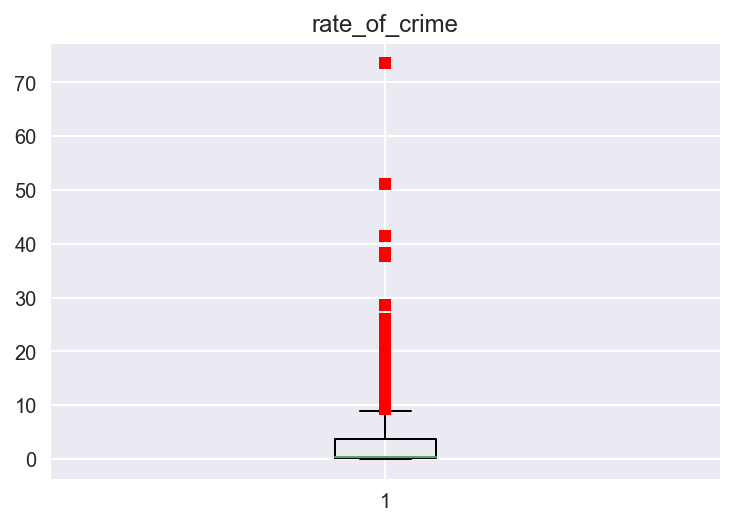

In [18]:
data = df.rate_of_crime
####  You don't need Seaborn. A simple boxplot with two "0" will do
####  plt.boxplot(data, 0, 'gD') ### this will show outliers in Green
####  plt.boxplot(data, 0, '')  #### This won't show outliers
####  plt.boxplot(data, 0, 'rs', 0)  #### this will show outliers horizontally
plt.figure()
plt.boxplot(data, 0, 'rs', 1)
plt.title(df.rate_of_crime.name)

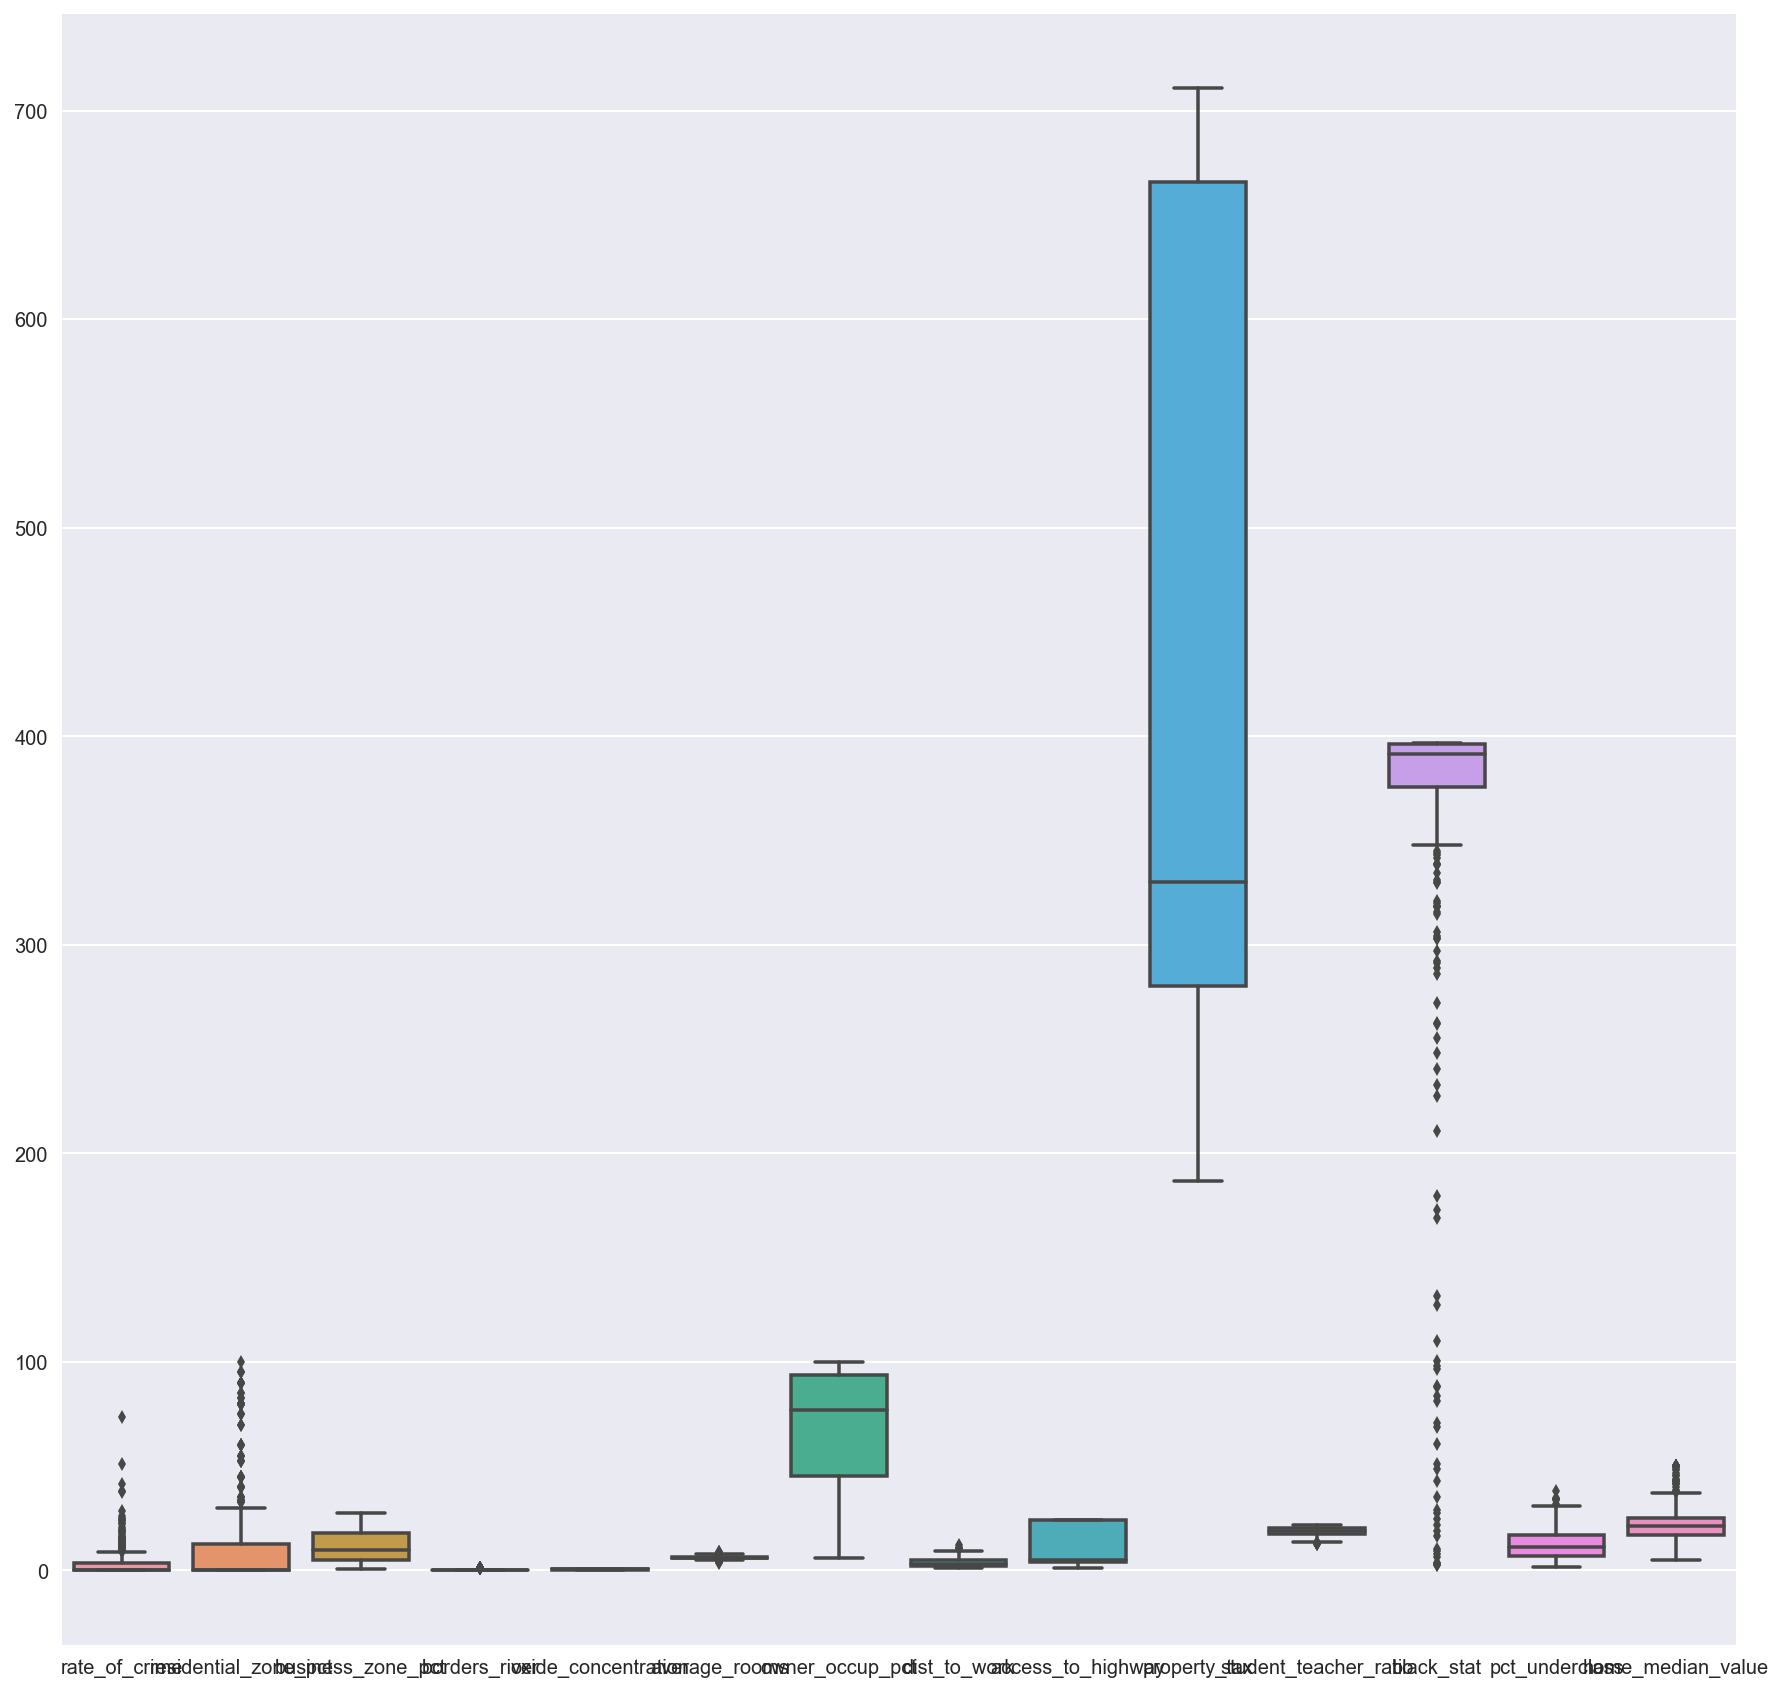

In [21]:
plt.figure(figsize=(15,15))
sns.boxplot(df)

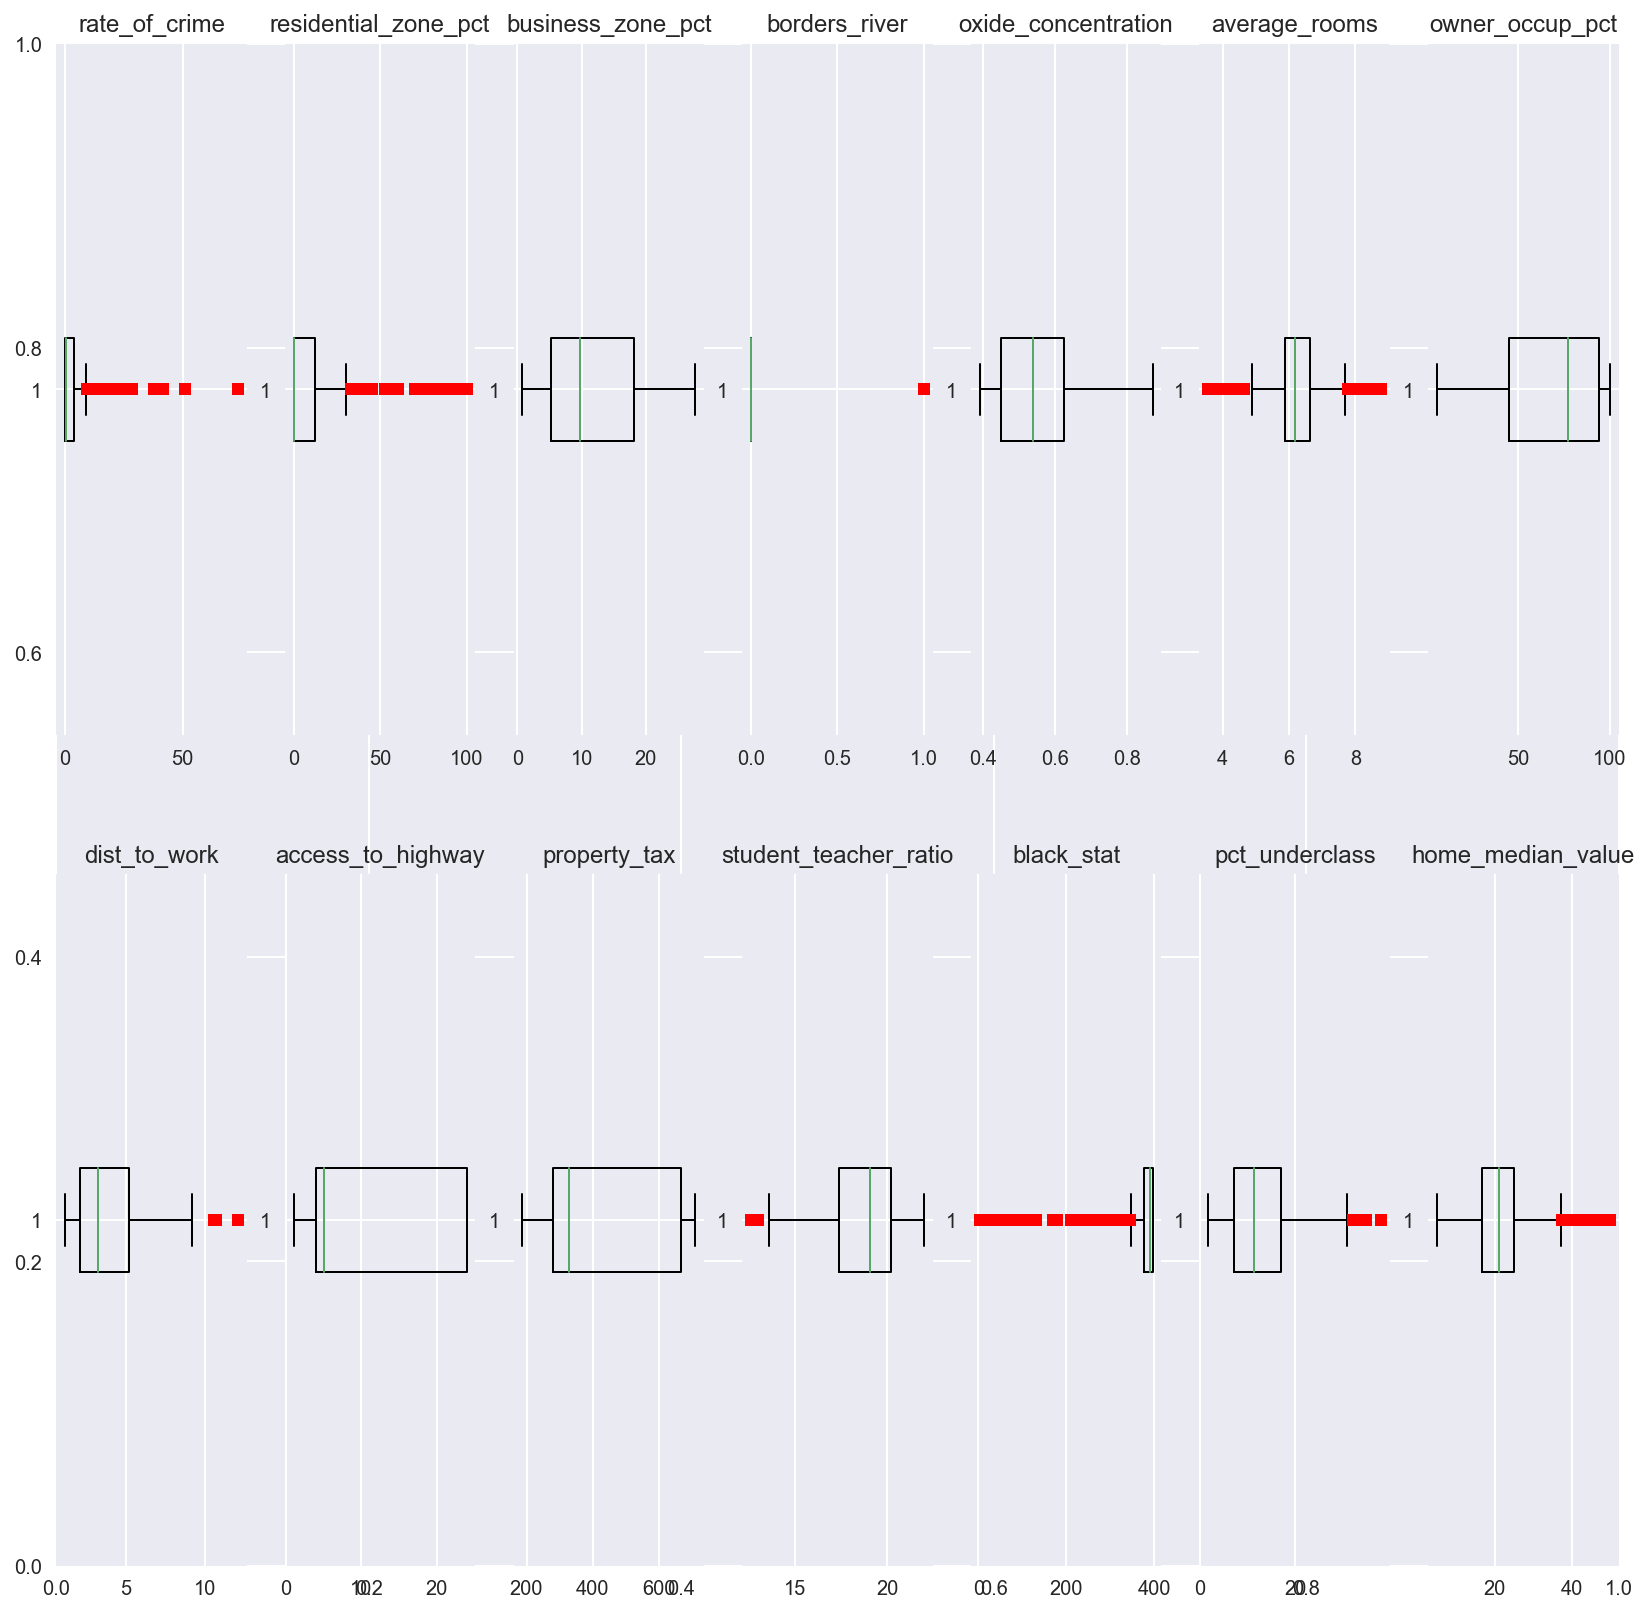

In [22]:
###### Plot all the variables in the dataset using a simple Loop to show Outliers in Red###
import pdb
numb = len(df.columns)
fig, ax = plt.subplots(figsize=(numb,numb))
for i in range(numb):
    ax = fig.add_subplot(2,numb/2,i+1)
    ax.boxplot(df[df.columns[i]], 0, 'rs', 0)  #### this will show outliers horizontally
    ax.set_title(df.columns[i])

In [23]:
##### Standardize all the variables in One step. But be careful !
####   All the variables must be numeric for this to work !!
df_norm = (df - df.mean()) / df.std()

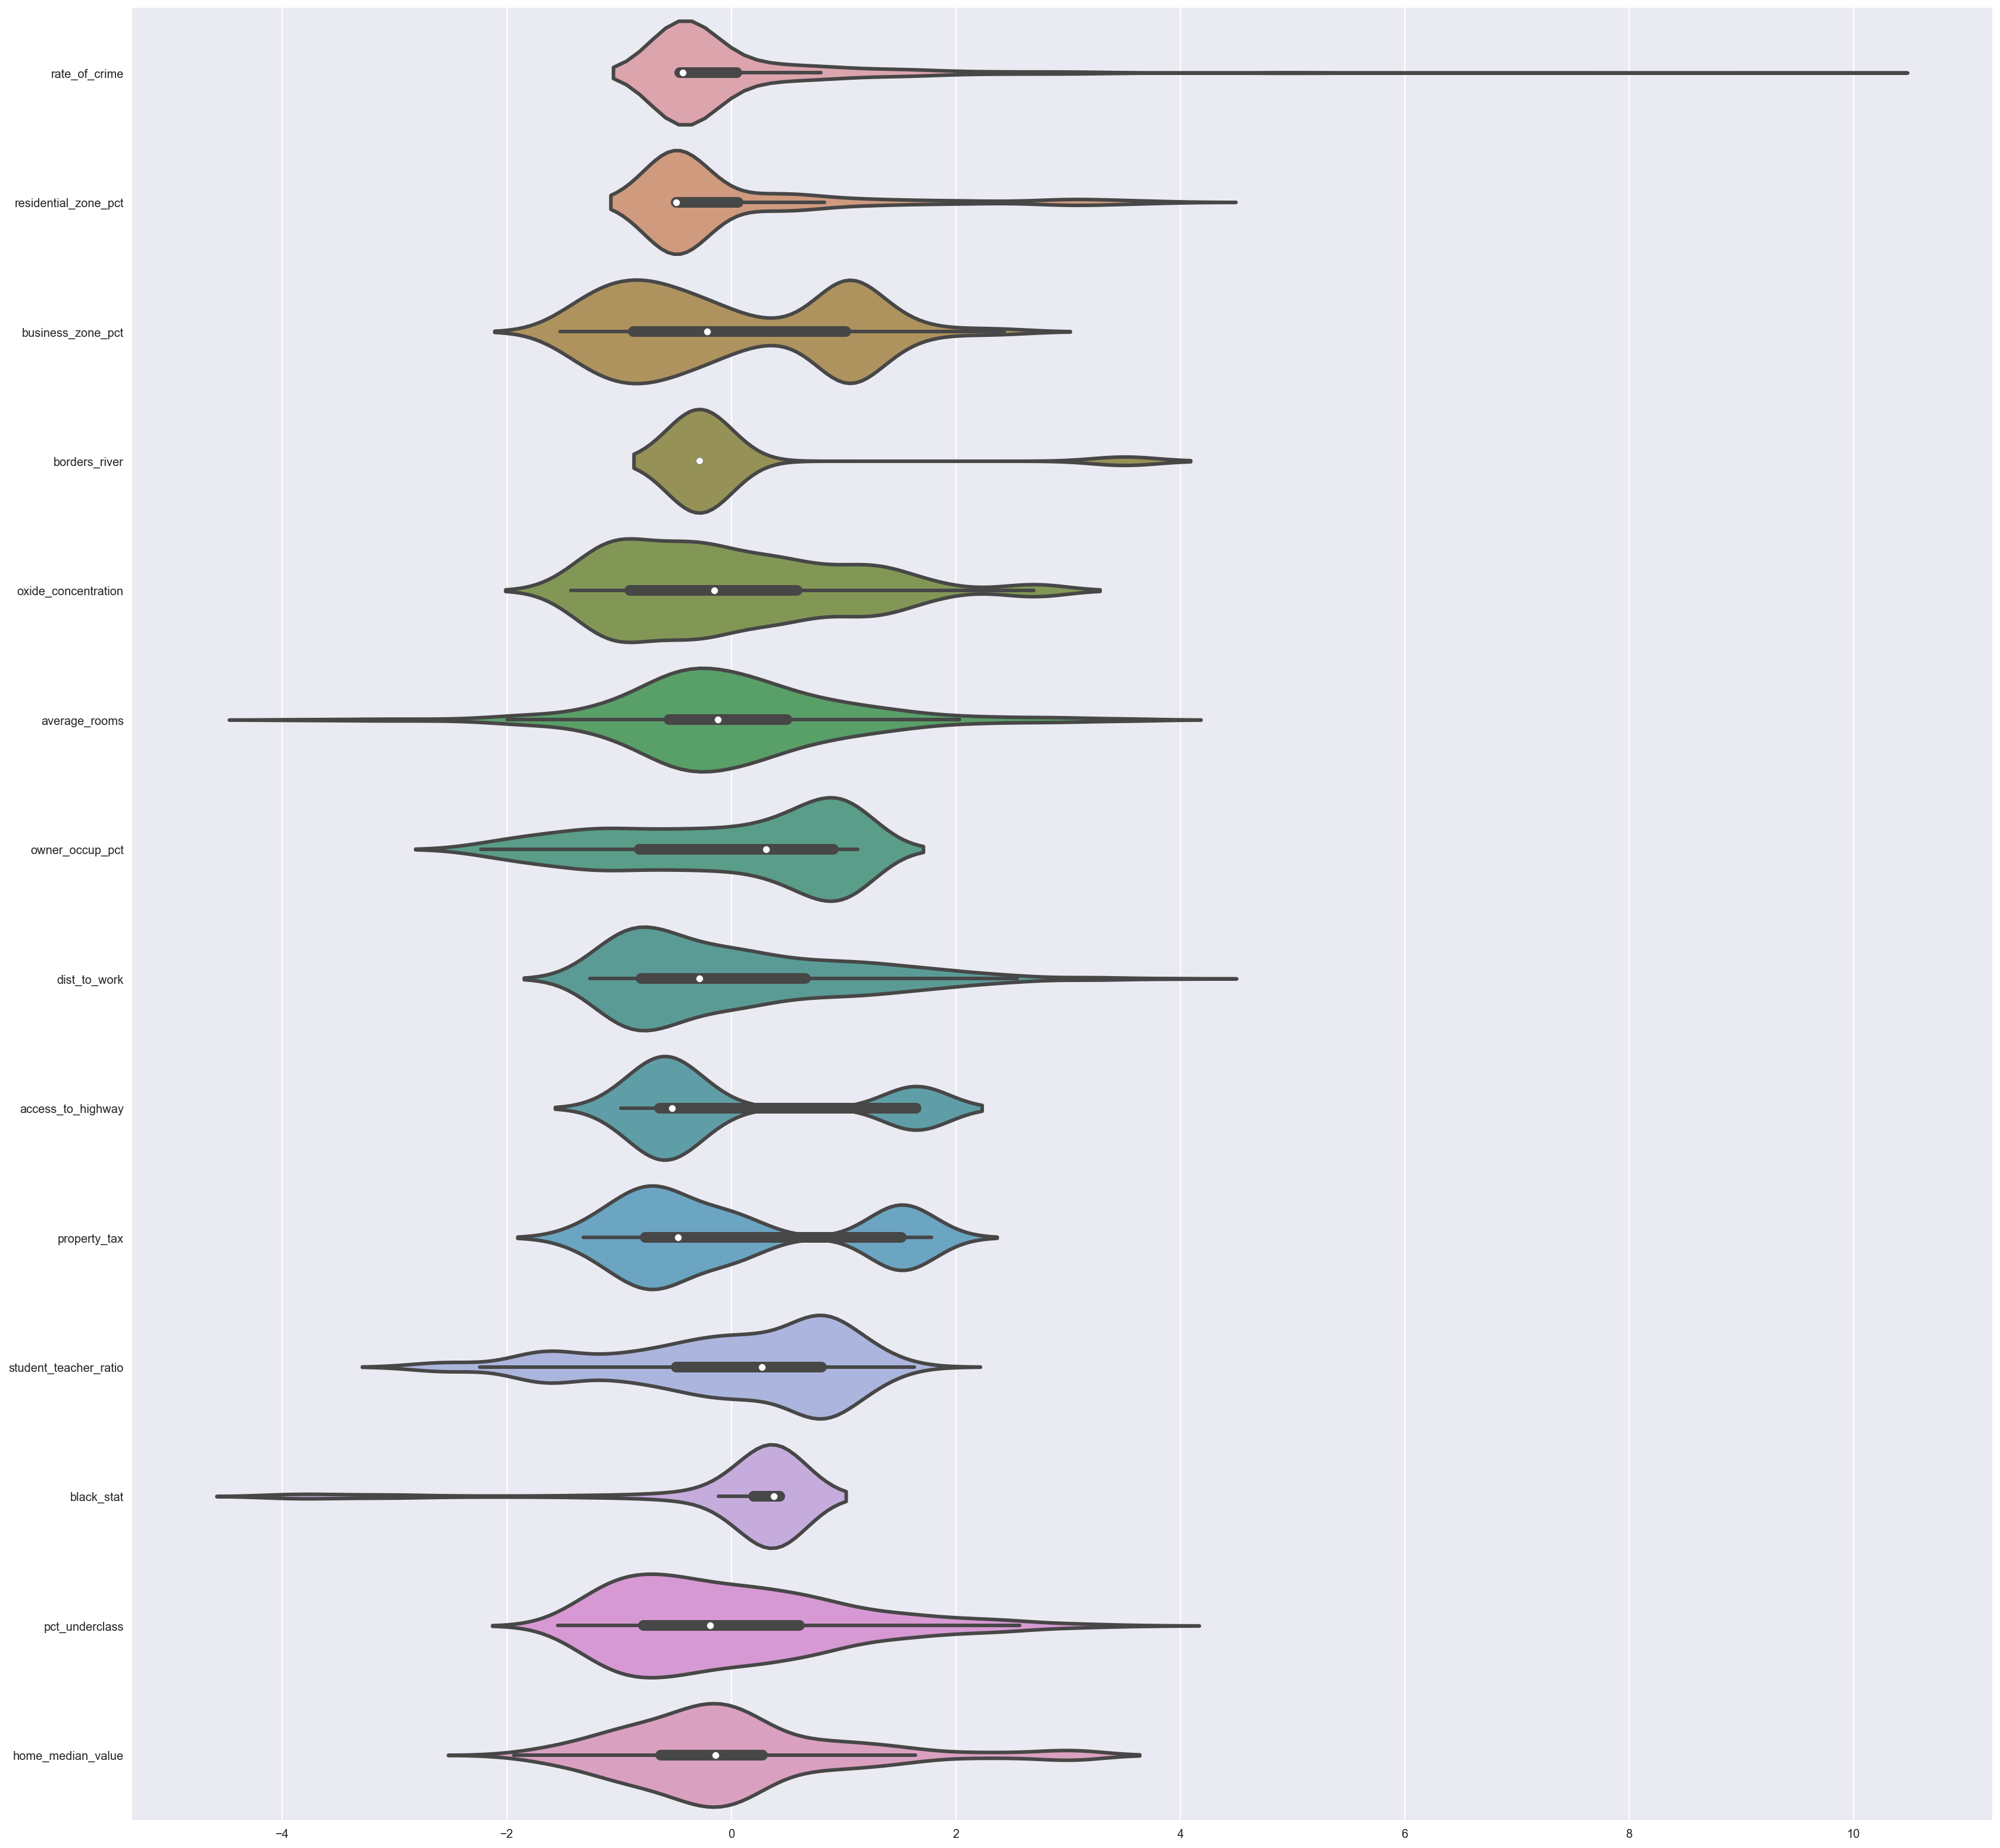

In [24]:
fig = plt.figure(figsize=(numb*2,numb*2))
ax = fig.gca()

ax = sns.violinplot(data=df_norm, orient='h', fliersize=5, scale='width',
                 linewidth=3, notch=False, saturation=0.5, ax=ax, inner='box')
plt.show()

In [26]:
corr = df.corr()

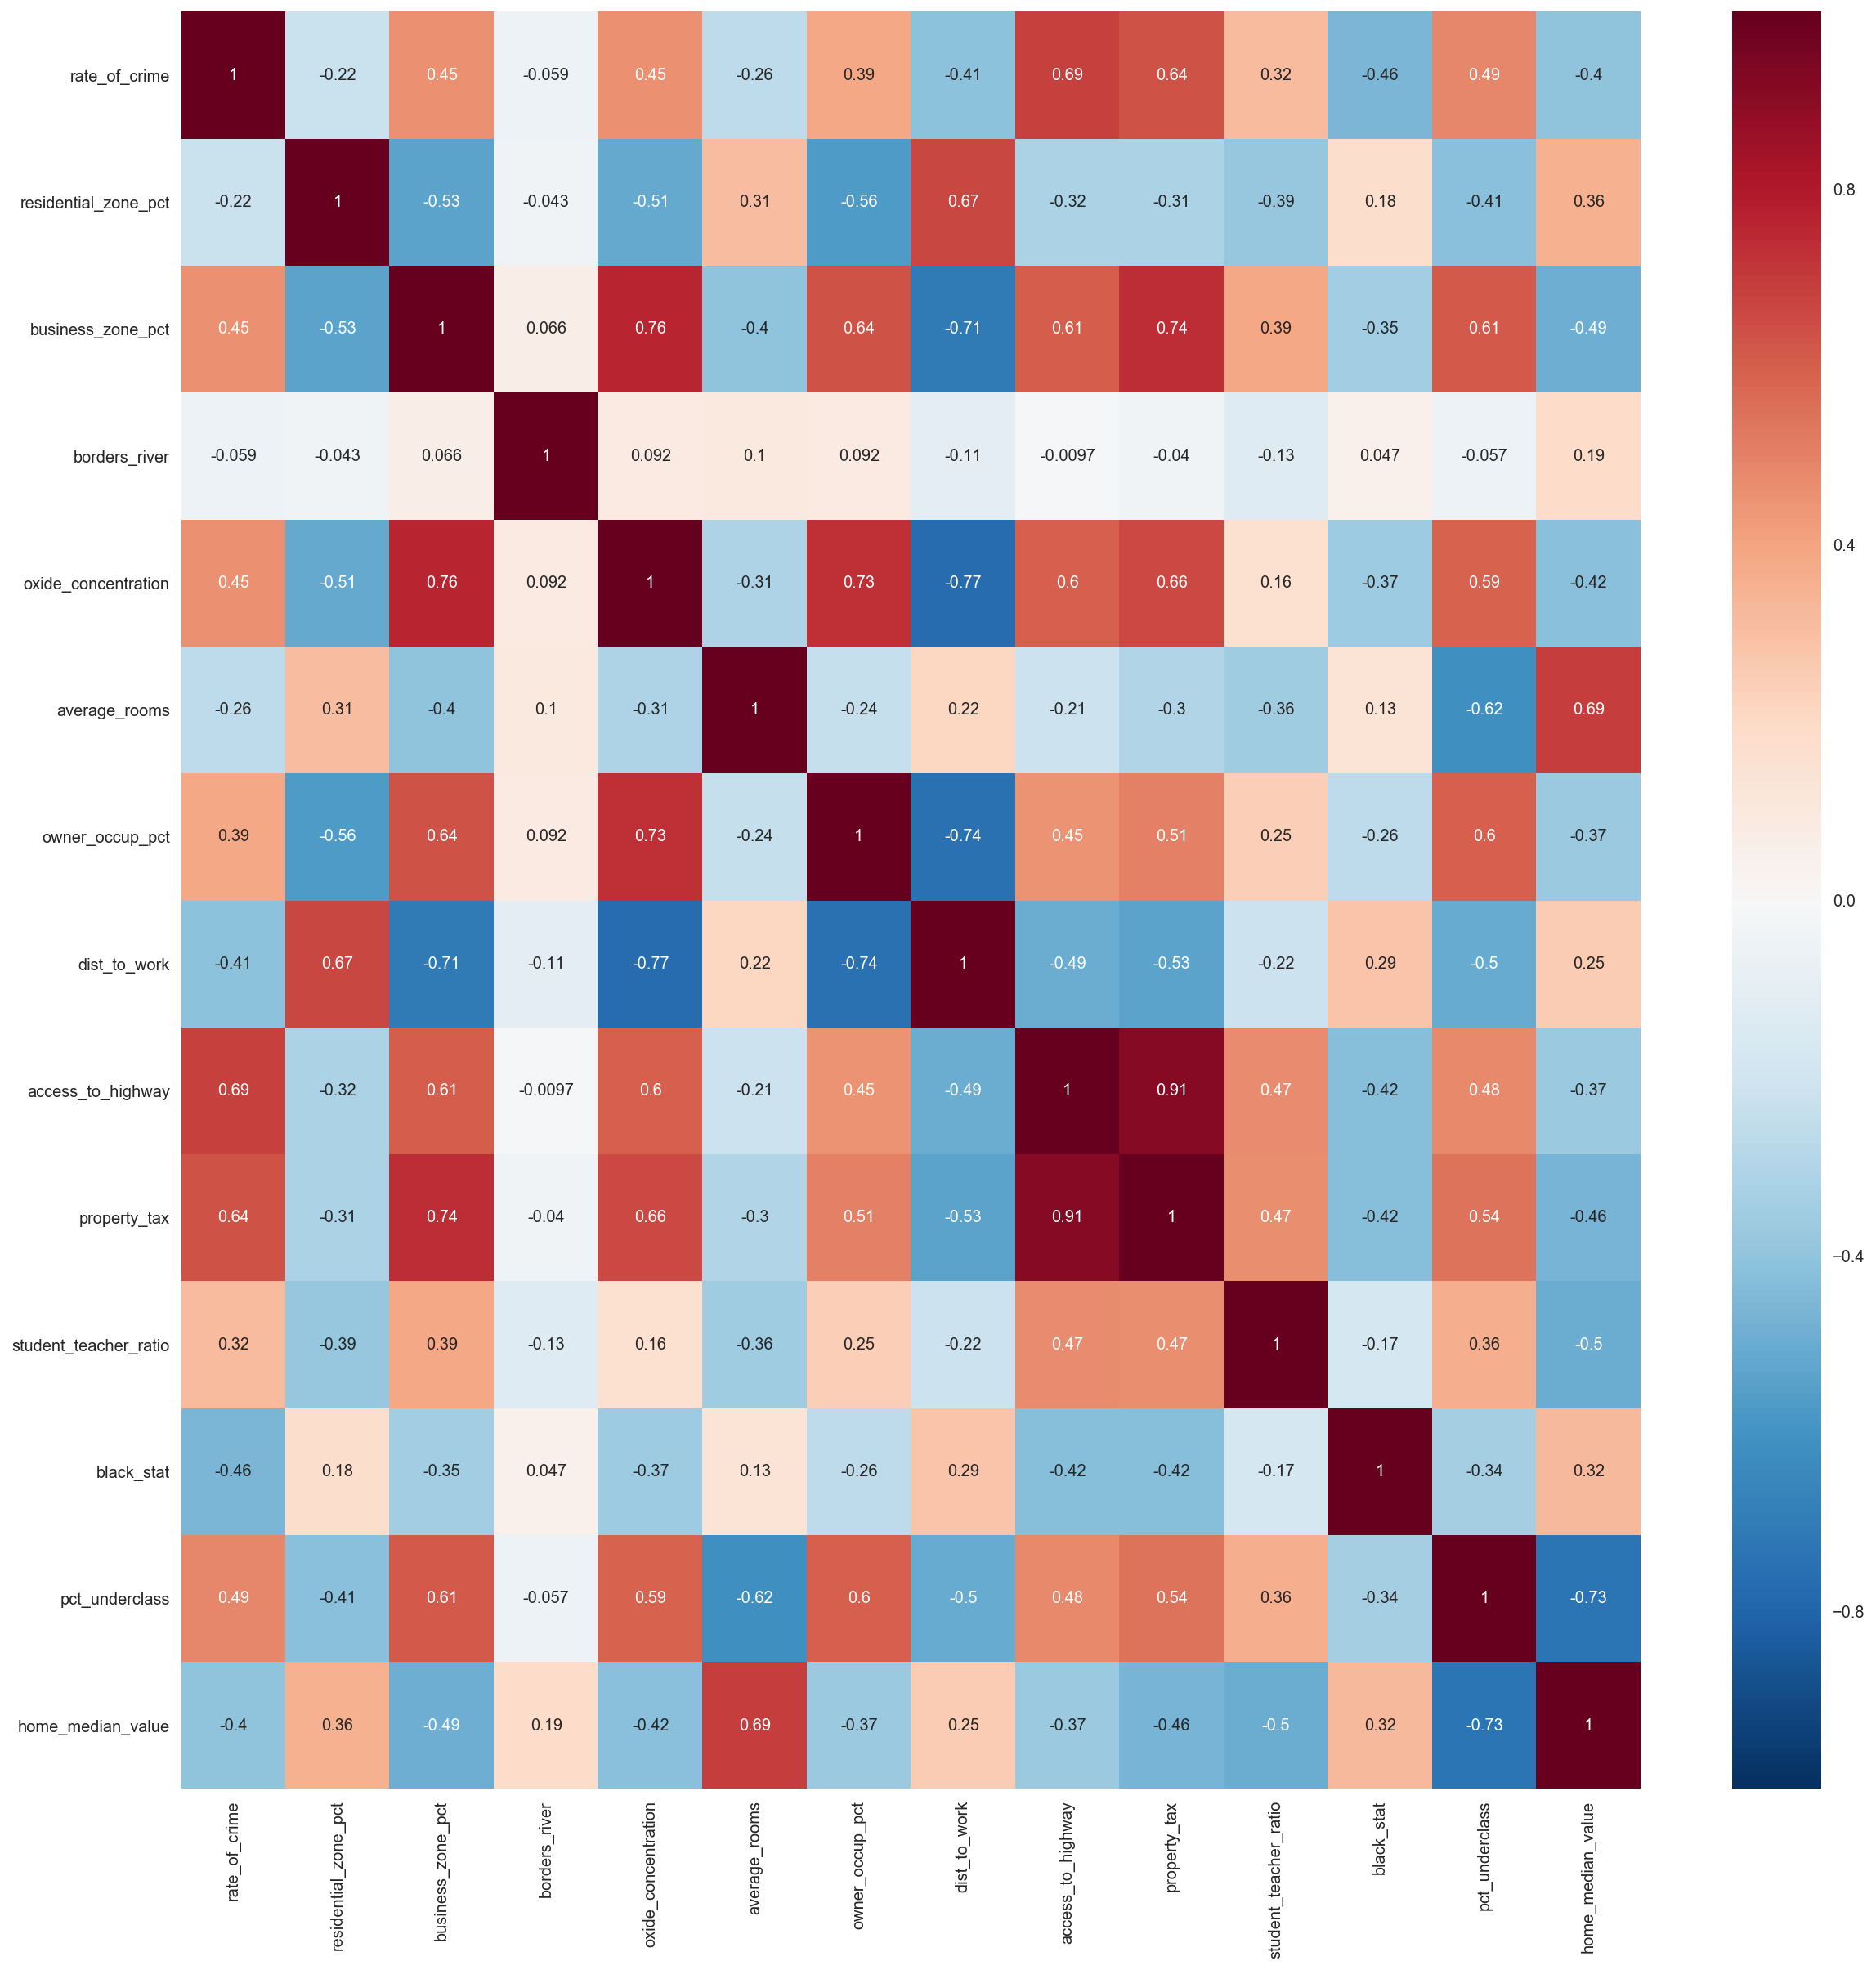

In [28]:
plt.figure(figsize=(20,20))
sns.heatmap(corr, annot=True)